# 05 · Análisis exploratorio y evaluación del modelo base

Ejecutar en el nodo primario de EMR con el kernel **American Tower - PySpark**, en un kernel nuevo y en orden. Cada celda muestra la evidencia que produce. Los registros de Spark y el resultado quedan enlazados por el identificador de corrida.

Parte del panel Gold y su contexto distrital. El análisis explora la disponibilidad de pruebas, la evolución
trimestral, la dispersión y las diferencias departamentales. Después compara persistencia y regresión lineal
para pronosticar el trimestre siguiente. Las imágenes aparecen debajo de su celda y se guardan en Operations.
El kernel del primario debe tener Matplotlib.

## 1. Configuración y período analítico

In [1]:
import pandas as pd
from IPython.display import display


def show_values(values):
    show_rows(values.items(), ["Indicador", "Valor"])


def show_rows(rows, columns=None):
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(rows, columns=columns))

REGION = "us-east-1"
OPERATIONS_BUCKET = "american-tower-dev-operations-1dd72256126674a5893dfca3df"
GOLD_RUN_URI = "s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T073334Z-7ea4f607ff/gold/_SUCCESS.json"  # Pegar la manifest_uri de entrada.
EXECUTORS = 10
EXECUTOR_CORES = 4
EXECUTOR_MEMORY = "8g"
EXECUTOR_OVERHEAD = "3g"
SHUFFLE_PARTITIONS = EXECUTORS * 12

show_values({"Región": REGION, "Manifiesto de entrada": GOLD_RUN_URI or "Pendiente de configurar", "Bucket Operations": OPERATIONS_BUCKET, "Executors solicitados": EXECUTORS})
show_values({"EDA": "2020-T1 a 2024-T4", "Unidad": "distrito-trimestre",
             "Horizonte del modelo": "un trimestre consecutivo"})

,Indicador,Valor
0,Región,us-east-1
1,Manifiesto de entrada,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T073334Z-7ea4f607ff/gold/_SUCCESS.json
2,Bucket Operations,american-tower-dev-operations-1dd72256126674a5893dfca3df
3,Executors solicitados,10


,Indicador,Valor
0,EDA,2020-T1 a 2024-T4
1,Unidad,distrito-trimestre
2,Horizonte del modelo,un trimestre consecutivo


## 2. Linaje y productos Gold

In [2]:
import json
import uuid
from datetime import datetime, timezone

import boto3
from botocore.config import Config
from botocore.exceptions import ClientError

s3 = boto3.client("s3", region_name=REGION, config=Config(retries={"mode": "standard", "max_attempts": 5}))
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:10]


def s3_path(uri):
    if not isinstance(uri, str) or not uri.startswith("s3://"):
        raise ValueError(f"Se requiere una URI S3 completa: {uri!r}")
    bucket, slash, key = uri.removeprefix("s3://").partition("/")
    if not bucket or not slash or not key:
        raise ValueError(f"Se requiere una URI S3 completa: {uri}")
    return bucket, key


def missing_object(error):
    return error.response["Error"]["Code"] in {"NoSuchKey", "NotFound", "404"}


def read_json(uri):
    bucket, key = s3_path(uri)
    try:
        response = s3.get_object(Bucket=bucket, Key=key)
    except ClientError as error:
        if missing_object(error):
            raise FileNotFoundError(f"No existe el manifiesto {uri}") from error
        raise
    with response["Body"] as stream:
        return json.load(stream)


def save_json(uri, value):
    bucket, key = s3_path(uri)
    s3.put_object(
        Bucket=bucket, Key=key, IfNoneMatch="*", ContentType="application/json",
        Body=json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False).encode("utf-8"),
    )
    return uri



def read_manifest(uri, schema, parameter):
    if not uri:
        raise ValueError(f"Completar {parameter} con la manifest_uri que devolvió la etapa anterior.")
    document = read_json(uri)
    if document.get("schema") != schema or document.get("complete") is not True or not document.get("run_id"):
        raise ValueError(f"Manifiesto incompleto o de un tipo diferente a {schema}: {uri}")
    return document
manifest = read_manifest(GOLD_RUN_URI, "gold-autonomo-v2", "GOLD_RUN_URI")
root = f"s3://{OPERATIONS_BUCKET}/run_id={RUN_ID}/analisis"
show_values({"Corrida Gold": manifest["run_id"], "Manifiesto Silver": manifest["silver_manifest_uri"],
             "Manifiesto Bronze": manifest["bronze_manifest_uri"], "Panel": manifest["panel_uri"],
             "Contexto": manifest["context_uri"], "Salida de evidencias": root})

/opt/american-tower/venv/lib64/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)


,Indicador,Valor
0,Corrida Gold,20261125T073334Z-7ea4f607ff
1,Manifiesto Silver,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T072542Z-e92a810559/silver/_SUCCESS.json
2,Manifiesto Bronze,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T071603Z-190d23d89e/bronze/_SUCCESS.json
3,Panel,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/run_id=20261125T073334Z-7ea4f607ff/panel_distrital
4,Contexto,s3://american-tower-dev-gold-00f4f2b4cf37bac32a9ec520ee/run_id=20261125T073334Z-7ea4f607ff/contexto_territorial
5,Salida de evidencias,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis


## 3. Inicialización de Spark en YARN

In [3]:
import os
import sys
from contextlib import contextmanager
from pathlib import Path

SPARK_HOME = Path("/usr/lib/spark")
py4j = sorted((SPARK_HOME / "python/lib").glob("py4j-*.zip"))
if not py4j:
    raise RuntimeError("Abrir esta notebook en el nodo primario de Amazon EMR con Spark instalado.")
os.environ["SPARK_HOME"] = str(SPARK_HOME)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
sys.path[:0] = [str(SPARK_HOME / "python"), str(py4j[0])]

from pyspark import SparkContext
from pyspark.sql import SparkSession, functions as F


@contextmanager
def spark_session(stage):
    if SparkContext._active_spark_context is not None:
        raise RuntimeError("Reiniciar el kernel para que YARN aplique los parámetros de esta corrida.")
    # EMRFS necesita un prefijo existente para el registro de eventos.
    log_dir = f"run_id={RUN_ID}/eventos_spark/"
    s3.put_object(Bucket=OPERATIONS_BUCKET, Key=log_dir, Body=b"")
    spark = (
        SparkSession.builder.master("yarn").appName(f"american-tower-{stage}")
        .config("spark.submit.deployMode", "client")
        .config("spark.pyspark.python", sys.executable)
        .config("spark.executorEnv.PYSPARK_PYTHON", sys.executable)
        .config("spark.dynamicAllocation.enabled", "false")
        .config("spark.executor.instances", str(EXECUTORS))
        .config("spark.executor.cores", str(EXECUTOR_CORES))
        .config("spark.executor.memory", EXECUTOR_MEMORY)
        .config("spark.executor.memoryOverhead", EXECUTOR_OVERHEAD)
        .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTITIONS))
        .config("spark.sql.session.timeZone", "UTC")
        .config("spark.eventLog.enabled", "true")
        .config("spark.eventLog.dir", f"s3://{OPERATIONS_BUCKET}/{log_dir}")
        .getOrCreate()
    )
    try:
        spark.sparkContext.setLogLevel("WARN")
        print(f"Aplicación Spark {spark.sparkContext.applicationId}", flush=True)
        yield spark
    finally:
        spark.stop()


from contextlib import ExitStack
from IPython import get_ipython
from urllib.parse import quote
from urllib.request import urlopen


def executor_usage(sc):
    if not sc.uiWebUrl:
        return {"estado": "interfaz Spark deshabilitada", "activos": None, "tareas": {}, "hosts": {}}
    app = quote(sc.applicationId, safe="")
    try:
        with urlopen(f"{sc.uiWebUrl.rstrip('/')}/api/v1/applications/{app}/allexecutors", timeout=4) as response:
            rows = [row for row in json.load(response) if row["id"] != "driver"]
    except (OSError, ValueError, KeyError) as error:
        return {"estado": f"interfaz no disponible ({type(error).__name__})",
                "activos": None, "tareas": {}, "hosts": {}}
    return {"estado": "lectura disponible", "activos": sum(row.get("isActive", False) for row in rows),
            "tareas": {row["id"]: row.get("totalTasks", 0) for row in rows},
            "hosts": {row["id"]: row.get("hostPort", "").rsplit(":", 1)[0] for row in rows}}


def show_spark(spark, events_uri):
    sc = spark.sparkContext
    show_values({"Aplicación": sc.applicationId, "Spark": spark.version, "Master": sc.master,
                 "Paralelismo base": sc.defaultParallelism, "Executors solicitados": EXECUTORS,
                 "vCores por executor": EXECUTOR_CORES,
                 "Heap y overhead por executor": f"{EXECUTOR_MEMORY} + {EXECUTOR_OVERHEAD}",
                 "Particiones shuffle": spark.conf.get("spark.sql.shuffle.partitions"),
                 "Eventos Spark": events_uri})


def open_stage(stage):
    events = get_ipython().events
    resources = ExitStack()

    def stop_on_failure(result):
        if result.error_before_exec or result.error_in_exec:
            resources.close()

    events.register("post_run_cell", stop_on_failure)
    resources.callback(events.unregister, "post_run_cell", stop_on_failure)
    try:
        spark = resources.enter_context(spark_session(stage))
    except BaseException:
        resources.close()
        raise
    events_uri = f"s3://{OPERATIONS_BUCKET}/run_id={RUN_ID}/eventos_spark/"
    return spark, resources, events_uri

spark, resources, events_uri = open_stage("analisis-modelo-base")
show_spark(spark, events_uri)

Nov 25, 2026 8:05:10 AM org.apache.spark.launcher.Log4jHotPatchOption staticJavaAgentOption

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/25 08:05:14 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


Aplicación Spark application_1795587001536_0008


,Indicador,Valor
0,Aplicación,application_1795587001536_0008
1,Spark,3.5.0-amzn-1
2,Master,yarn
3,Paralelismo base,2
4,Executors solicitados,10
5,vCores por executor,4
6,Heap y overhead por executor,8g + 3g
7,Particiones shuffle,120
8,Eventos Spark,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/eventos_spark/


## 4. Universo analítico y disponibilidad de mediciones

El indicador observado describe disponibilidad de pruebas en el panel. Las filas sin medición conservan valores nulos.

In [4]:
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import Image
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

ANALYSIS_START, ANALYSIS_END = 2020, 2024
TEAL = "#176B72"
AMBER = "#B75D2B"


def persist_figure(fig, root, name):
    uri = f"{root}/{name}"
    bucket, key = s3_path(uri)
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=160, bbox_inches="tight", facecolor="white")
        data = buffer.getvalue()
    plt.close(fig)
    display(Image(data=data))
    s3.put_object(Bucket=bucket, Key=key, Body=data, ContentType="image/png", IfNoneMatch="*")
    print(uri, flush=True)
    return uri


def finite_records(frame):
    return frame.astype(object).where(frame.notna(), None).to_dict("records")


def panel_quality(panel, context, manifest):
    stats = panel.agg(F.count("*").alias("filas"),
                      F.count_distinct(F.struct("ubigeo", "period_id")).alias("claves"),
                      F.count("vel_descarga_mbps").alias("observadas"),
                      F.count_distinct("ubigeo").alias("distritos"),
                      F.count_distinct("period_id").alias("trimestres")).first().asDict()
    required = set(range(ANALYSIS_START * 4, (ANALYSIS_END + 1) * 4))
    periods = {row.period_id for row in panel.select("period_id").distinct().collect()}
    if periods != required or stats["distritos"] != manifest["panel"]["distritos"]:
        raise ValueError("El EDA requiere los distritos de Gold y todos los trimestres de 2020 a 2024.")
    if (stats["filas"] != stats["claves"] or stats["filas"] != stats["distritos"] * len(required)
            or not stats["observadas"]):
        raise ValueError("El panel del EDA no cumple el grano distrito-trimestre.")
    stats["sin_medicion"] = stats["filas"] - stats["observadas"]
    stats["observadas_pct"] = 100 * stats["observadas"] / stats["filas"]
    stats["distritos_sin_medicion"] = (panel.groupBy("ubigeo").agg(F.count("vel_descarga_mbps").alias("n"))
                                     .filter("n = 0").count())
    stats["contexto"] = context.agg(F.count("*").alias("distritos"),
                                     F.count("poblacion_2020").alias("con_worldpop"),
                                     F.count("centros_en_reporte").alias("con_osiptel")).first().asDict()
    return stats

panel = spark.read.parquet(manifest["panel_uri"]).filter(F.col("year").between(ANALYSIS_START, ANALYSIS_END)).cache()
resources.callback(panel.unpersist)
context = spark.read.parquet(manifest["context_uri"]).cache()
resources.callback(context.unpersist)
last_quarter = panel.filter((F.col("year") == ANALYSIS_END) & (F.col("quarter") == 4))
quality = panel_quality(panel, context, manifest)
show_values({k: (round(v, 2) if isinstance(v, float) else v) for k, v in quality.items() if k != "contexto"})
show_values(quality["contexto"])
panel.orderBy(F.col("period_id").desc(), "ubigeo").select(
    "ubigeo", "departamento", "year", "quarter", "vel_descarga_mbps", "tests", "observado"
).show(8, truncate=False)

,Indicador,Valor
0,filas,37800.00
1,claves,37800.00
2,observadas,29161.00
3,distritos,1890.00
4,trimestres,20.00
5,sin_medicion,8639.00
6,observadas_pct,77.15
7,distritos_sin_medicion,16.00


,Indicador,Valor
0,distritos,1890
1,con_worldpop,1890
2,con_osiptel,1663


+------+------------+----+-------+------------------+-----+---------+
|ubigeo|departamento|year|quarter|vel_descarga_mbps |tests|observado|
+------+------------+----+-------+------------------+-----+---------+
|010101|AMAZONAS    |2024|4      |29.891694704049847|321  |true     |
|010102|AMAZONAS    |2024|4      |82.921            |11   |true     |
|010103|AMAZONAS    |2024|4      |NULL              |NULL |false    |
|010104|AMAZONAS    |2024|4      |NULL              |NULL |false    |
|010105|AMAZONAS    |2024|4      |NULL              |NULL |false    |
|010106|AMAZONAS    |2024|4      |NULL              |NULL |false    |
|010107|AMAZONAS    |2024|4      |24.513            |3    |true     |
|010108|AMAZONAS    |2024|4      |NULL              |NULL |false    |
+------+------------+----+-------+------------------+-----+---------+
only showing top 8 rows



## 5. Evolución trimestral y cobertura de observación

La franja muestra la dispersión entre distritos observados. La serie inferior muestra qué proporción del universo se observó cada trimestre.

,periodo,universo,observados,observados_pct,p25,p50,p75
0,2020-T1,1890,1231,65.13,7.37,14.08,22.65
1,2020-T2,1890,1111,58.78,5.67,11.89,19.61
2,2020-T3,1890,1394,73.76,6.24,12.53,20.48
3,2020-T4,1890,1453,76.88,7.81,13.56,21.07
4,2021-T1,1890,1381,73.07,7.48,13.19,20.79
5,2021-T2,1890,1465,77.51,8.10,15.11,22.72
6,2021-T3,1890,1496,79.15,8.10,14.92,22.96
7,2021-T4,1890,1472,77.88,8.64,15.49,24.27
8,2022-T1,1890,1498,79.26,10.21,16.50,24.33
9,2022-T2,1890,1474,77.99,11.28,18.60,27.76


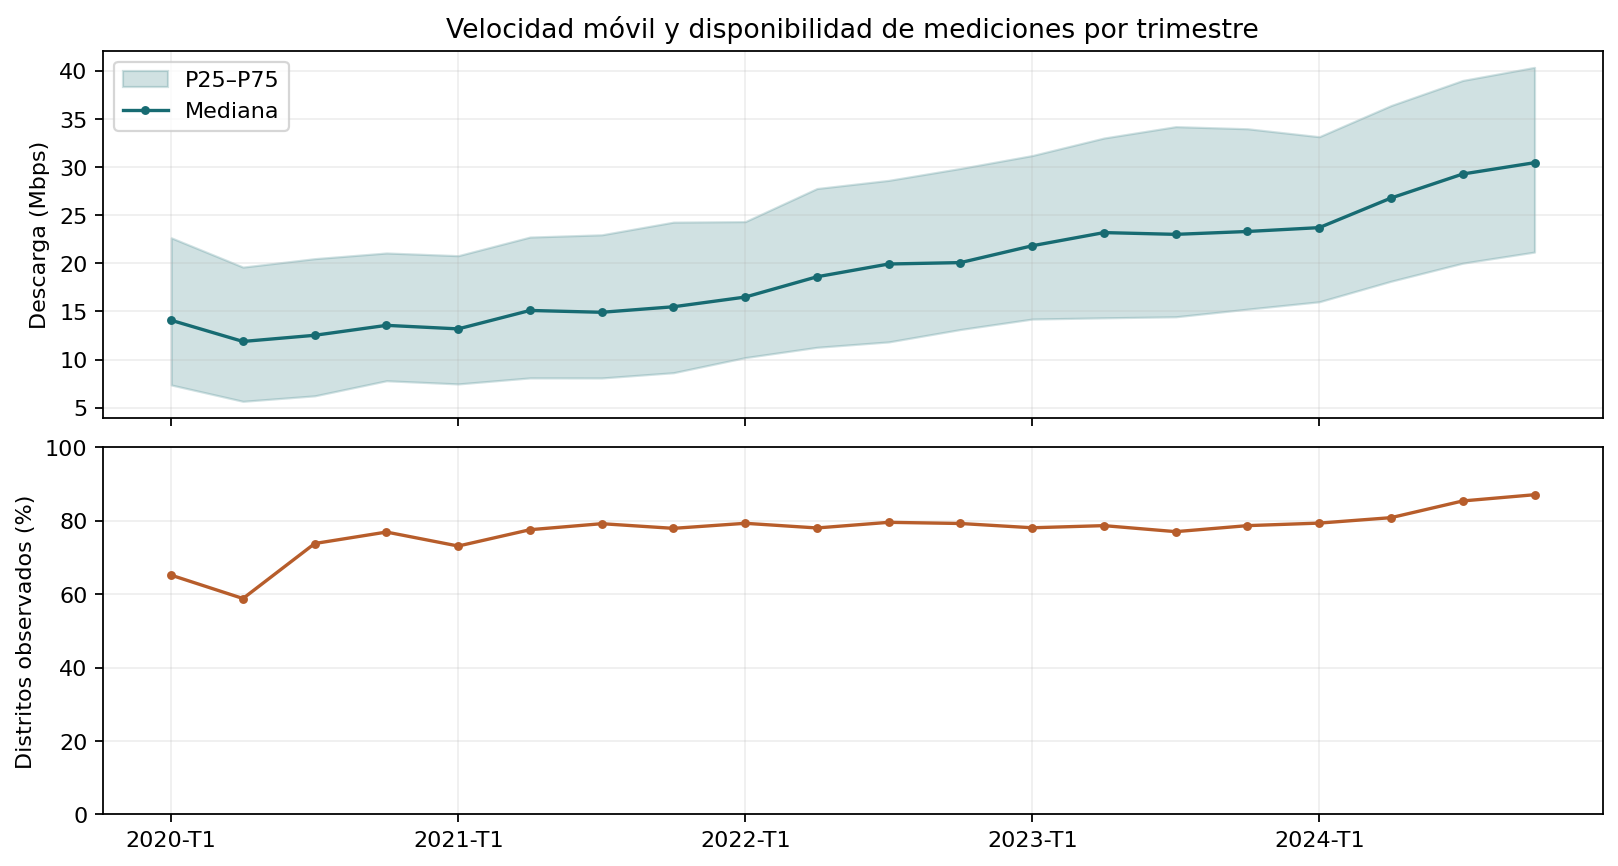

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_trimestres.png


In [5]:
def trend(panel, root):
    periods = (panel.groupBy("period_id", "year", "quarter").agg(
        F.count("*").alias("universo"), F.count("vel_descarga_mbps").alias("observados"),
        F.percentile_approx("vel_descarga_mbps", [0.25, 0.5, 0.75], 10000).alias("cuartiles"),
    ).orderBy("period_id"))
    table = periods.select(
        "year", "quarter", "universo", "observados",
        *[F.col("cuartiles")[index].alias(name) for index, name in enumerate(("p25", "p50", "p75"))],
    ).toPandas()
    table["periodo"] = [f"{r.year}-T{r.quarter}" for r in table.itertuples()]
    table["observados_pct"] = 100 * table.observados / table.universo
    display(table[["periodo", "universo", "observados", "observados_pct", "p25", "p50", "p75"]].round(2))
    x = list(range(len(table)))
    fig, axes = plt.subplots(2, 1, figsize=(10, 5.3), sharex=True, constrained_layout=True)
    axes[0].fill_between(x, table.p25.to_numpy(dtype=float), table.p75.to_numpy(dtype=float), alpha=.2, color=TEAL, label="P25–P75")
    axes[0].plot(x, table.p50.to_numpy(dtype=float), "o-", color=TEAL, markersize=3, label="Mediana")
    axes[0].set(title="Velocidad móvil y disponibilidad de mediciones por trimestre", ylabel="Descarga (Mbps)")
    axes[0].legend(loc="best")
    axes[1].plot(x, table.observados_pct, "o-", color=AMBER, markersize=3)
    axes[1].set(ylabel="Distritos observados (%)", ylim=(0, 100))
    axes[1].set_xticks(x[::4])
    axes[1].set_xticklabels(table.periodo.iloc[::4])
    for ax in axes:
        ax.grid(alpha=.2)
    return finite_records(table), persist_figure(fig, root, "eda_trimestres.png")


quarterly, chart_trend = trend(panel, root)

## 6. Comparación departamental de descarga

Cada barra usa la mediana entre distritos observados. El denominador indica cuántos distritos integran cada departamento.

,departamento,universo,observados,mediana_mbps,observados_pct
0,LIMA,171,137,37.83,80.12
1,ICA,43,43,35.87,100.00
2,MADRE DE DIOS,11,11,34.48,100.00
3,LAMBAYEQUE,38,38,33.55,100.00
4,CALLAO,7,7,33.15,100.00
5,TUMBES,13,13,32.31,100.00
6,HUANCAVELICA,102,85,31.84,83.33
7,AREQUIPA,109,93,31.55,85.32
8,CAJAMARCA,127,110,30.96,86.61
9,CUSCO,116,116,30.43,100.00


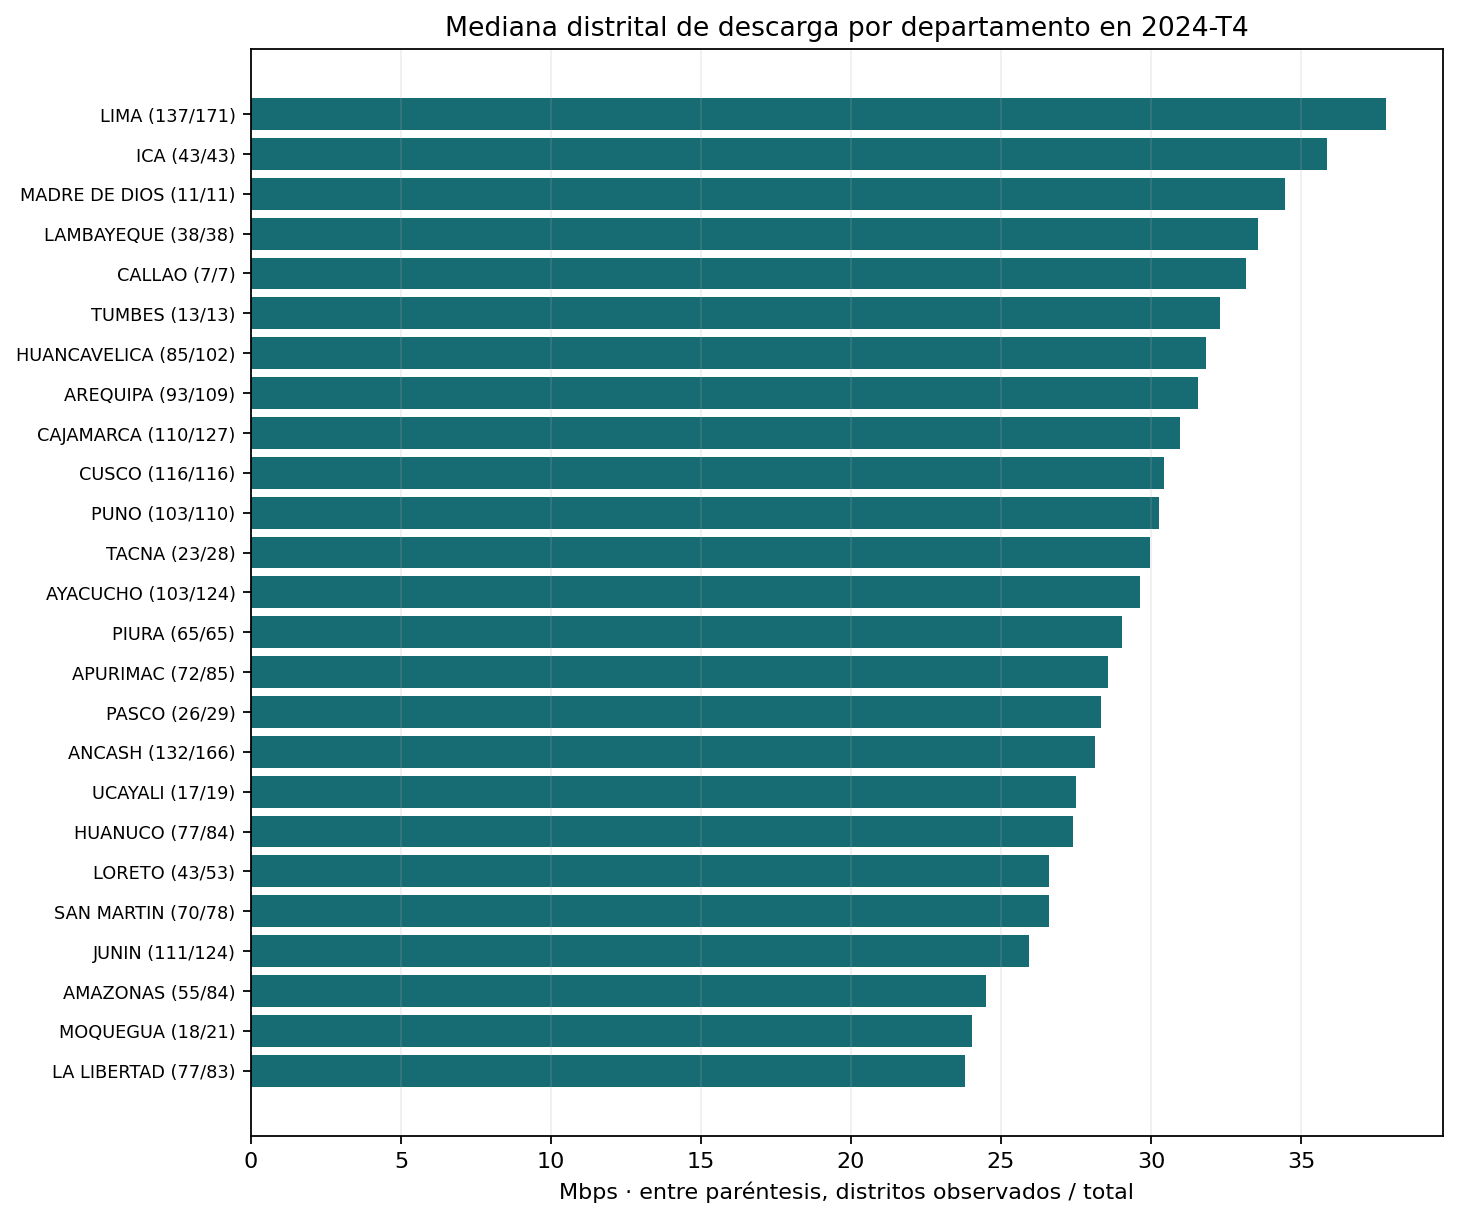

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_departamentos.png


In [6]:
def department_summary(last_quarter, root):
    table = (last_quarter.groupBy("departamento").agg(
        F.count("*").alias("universo"), F.count("vel_descarga_mbps").alias("observados"),
        F.median("vel_descarga_mbps").alias("mediana_mbps"),
    ).orderBy(F.col("mediana_mbps").desc_nulls_last(), "departamento").toPandas())
    table["observados_pct"] = 100 * table.observados / table.universo
    display(table.round(2))
    graph = table.dropna(subset=["mediana_mbps"]).sort_values("mediana_mbps")
    if graph.empty:
        raise ValueError("La comparación departamental requiere mediciones en 2024-T4.")
    fig, ax = plt.subplots(figsize=(9, 7.5), constrained_layout=True)
    ax.barh([f"{row.departamento} ({row.observados}/{row.universo})" for row in graph.itertuples()],
            graph.mediana_mbps, color=TEAL)
    ax.tick_params(axis="y", labelsize=8)
    ax.set(title="Mediana distrital de descarga por departamento en 2024-T4",
           xlabel="Mbps · entre paréntesis, distritos observados / total")
    ax.grid(axis="x", alpha=.2)
    return finite_records(table), persist_figure(fig, root, "eda_departamentos.png")


departmental, chart_dept = department_summary(last_quarter, root)

## 7. Distribución distrital de descarga en 2024-T4

,Indicador,Valor
0,distritos_observados,1645.000000
1,min_mbps,0.049000
2,max_mbps,295.313000
3,p10,12.874221
4,p25,21.167084
5,p50,30.446765
6,p75,40.344750
7,p90,54.050525


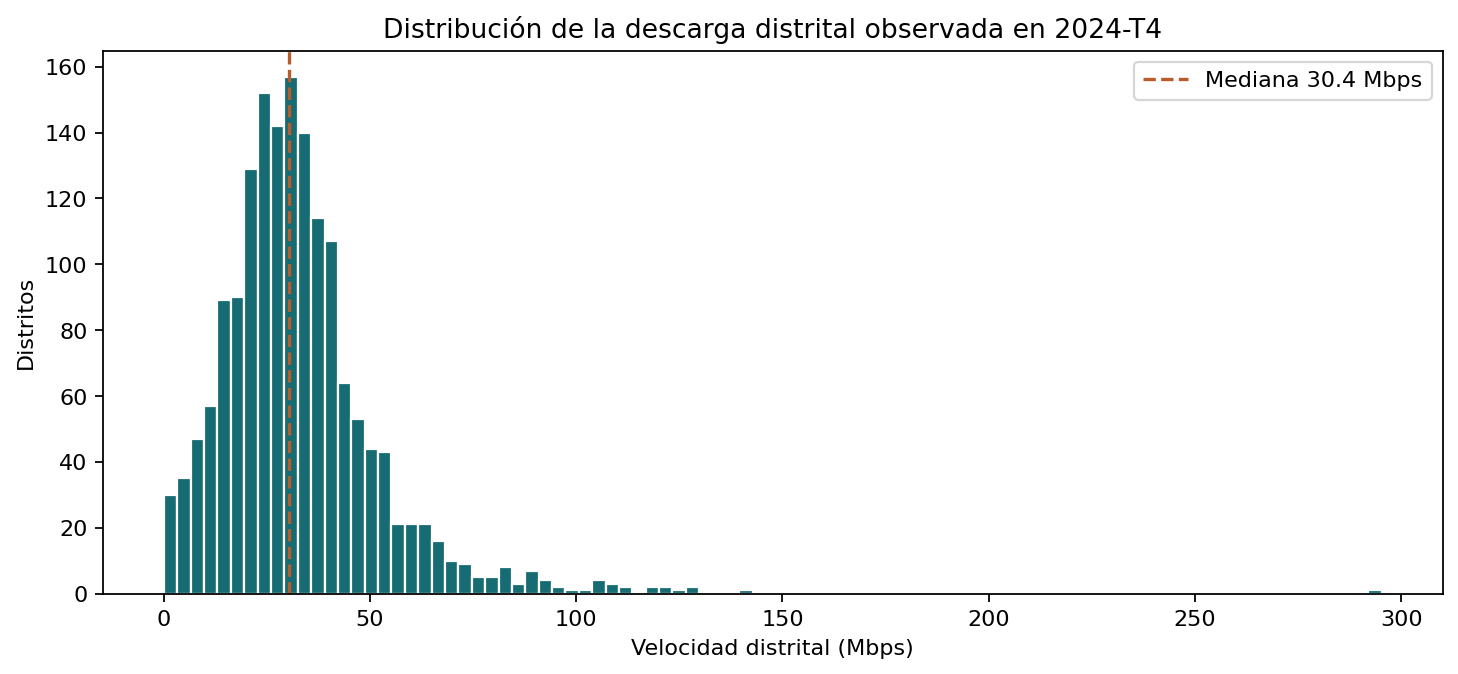

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_distribucion_2024_t4.png


In [7]:
def dispersion(last_quarter, max_districts, root):
    speeds = last_quarter.filter("observado").select("vel_descarga_mbps").limit(max_districts + 1).toPandas()
    if speeds.empty or len(speeds) > max_districts:
        raise ValueError("Cantidad de velocidades incompatibles con el universo distrital declarado.")
    values = speeds.vel_descarga_mbps
    quantiles = {f"p{int(100*p)}": float(value)
                 for p, value in values.quantile([.10, .25, .50, .75, .90]).items()}
    stats = {"distritos_observados": len(values), "min_mbps": float(values.min()),
             "max_mbps": float(values.max()), **quantiles}
    show_values(stats)
    fig, ax = plt.subplots(figsize=(9, 4.1), constrained_layout=True)
    ax.hist(values, bins="auto", color=TEAL, edgecolor="white")
    ax.axvline(quantiles["p50"], color=AMBER, linestyle="--", label=f"Mediana {quantiles['p50']:.1f} Mbps")
    ax.set(title="Distribución de la descarga distrital observada en 2024-T4",
           xlabel="Velocidad distrital (Mbps)", ylabel="Distritos")
    ax.legend()
    return stats, persist_figure(fig, root, "eda_distribucion_2024_t4.png")


speed_stats, chart_speeds = dispersion(last_quarter, quality["distritos"], root)

## 8. Población distrital y soporte de las pruebas

La correlación de Spearman resume la asociación entre población estimada y cantidad de pruebas en los distritos elegibles.

,Indicador,Valor
0,distritos_en_grafica,1645.000000
1,universo_distrital,1890.000000
2,spearman,0.705858


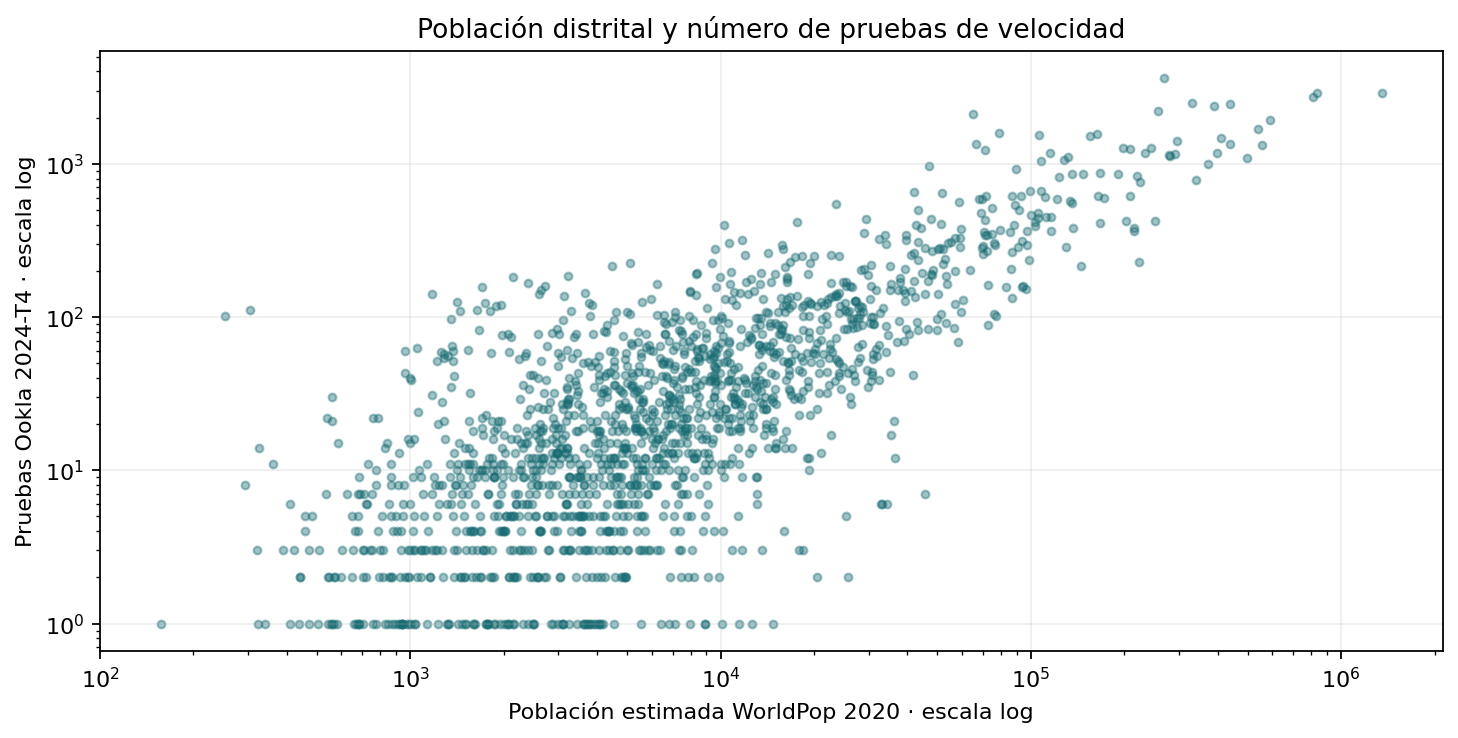

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_poblacion_pruebas.png


In [8]:
def population_support(last_quarter, context, max_districts, root):
    eligible = (last_quarter.select("ubigeo", "tests").join(context.select("ubigeo", "poblacion_2020"), "ubigeo")
                .filter("tests > 0 AND poblacion_2020 > 0"))
    sample = eligible.limit(max_districts + 1).toPandas()
    if sample.empty or len(sample) > max_districts:
        raise ValueError("Revisar la unión distrital de WorldPop y Ookla.")
    correlation = sample.poblacion_2020.rank().corr(sample.tests.rank())
    summary = {"distritos_en_grafica": len(sample), "universo_distrital": max_districts,
               "spearman": None if pd.isna(correlation) else float(correlation)}
    show_values(summary)
    fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
    ax.scatter(sample.poblacion_2020, sample.tests, color=TEAL, alpha=.4, s=12)
    ax.set(xscale="log", yscale="log", title="Población distrital y número de pruebas de velocidad",
           xlabel="Población estimada WorldPop 2020 · escala log", ylabel="Pruebas Ookla 2024-T4 · escala log")
    ax.grid(alpha=.2)
    return summary, persist_figure(fig, root, "eda_poblacion_pruebas.png")


population_stats, chart_pop = population_support(last_quarter, context, quality["distritos"], root)

## 9. Cobertura 4G declarada en la instantánea OSIPTEL

El denominador son los centros poblados con declaración interpretable. La fecha de corte figura en el contexto Gold.

,Indicador,Valor
0,periodo,202303
1,fecha_corte,2023-06-13


,departamento,centros_con_declaracion,centros_4g,porcentaje_4g
0,CALLAO,6,6,100.00
1,ICA,739,522,70.64
2,LIMA,1636,1140,69.68
3,LAMBAYEQUE,938,595,63.43
4,TUMBES,127,79,62.20
5,MOQUEGUA,241,146,60.58
6,TACNA,310,183,59.03
7,AREQUIPA,1250,708,56.64
8,PASCO,675,374,55.41
9,JUNIN,1500,789,52.60


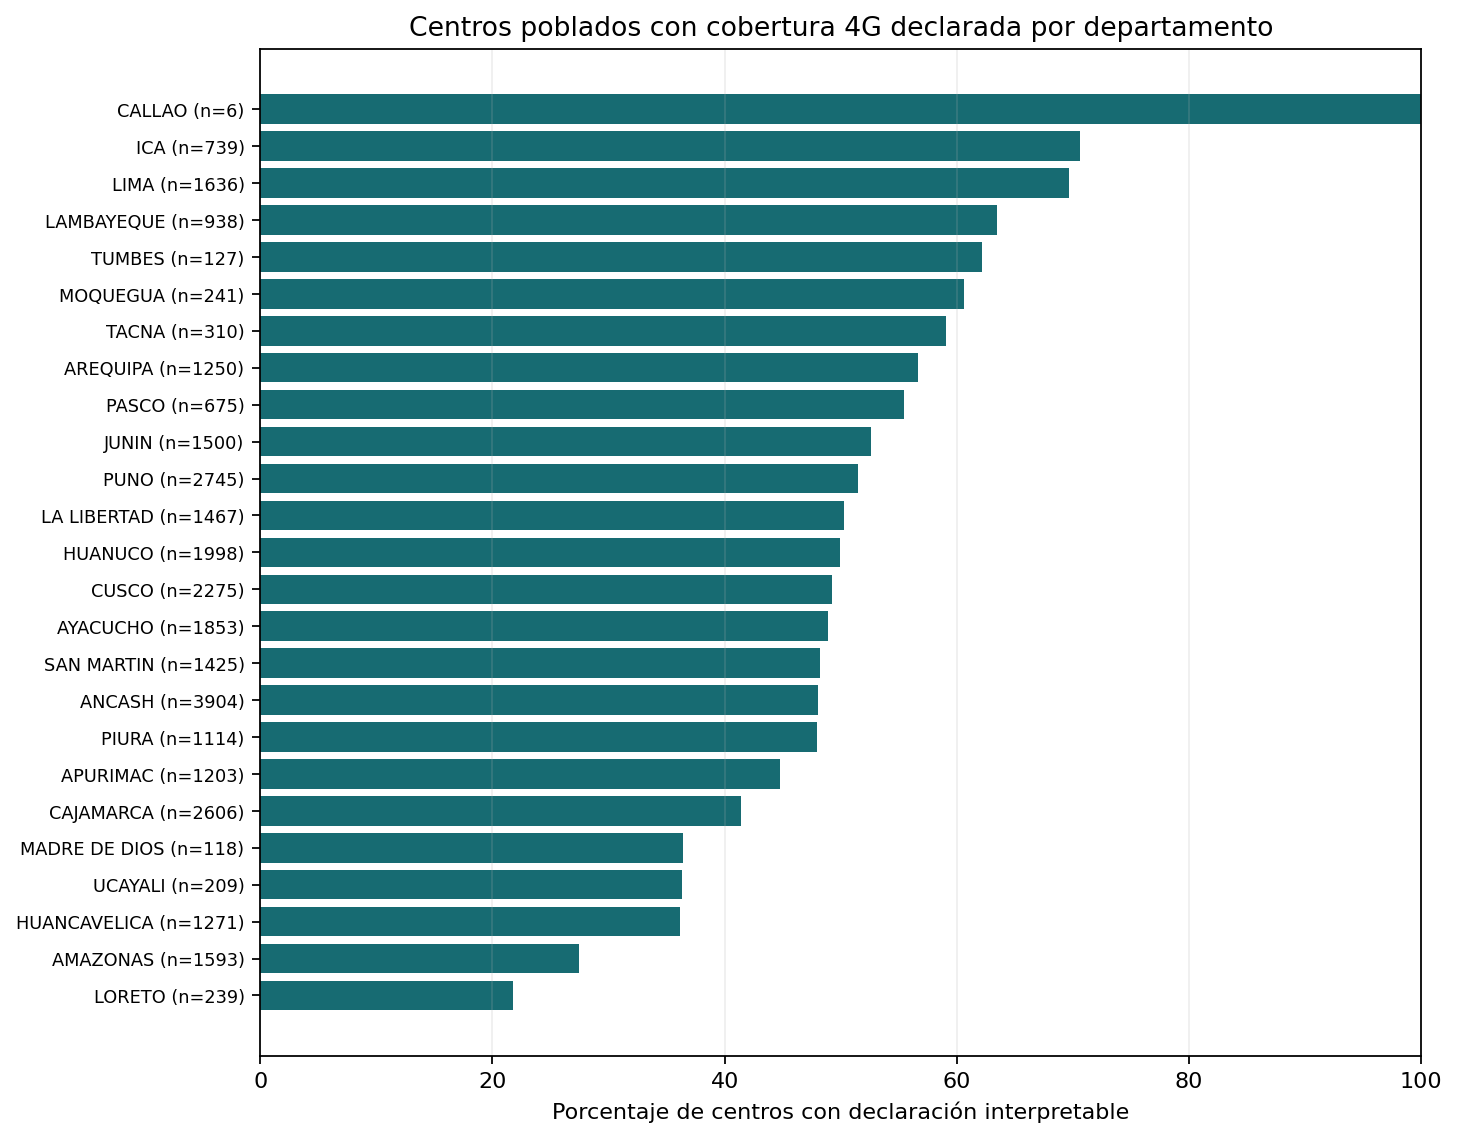

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_osiptel_4g.png


In [9]:
def declared_coverage(context, root):
    table = (context.groupBy("departamento").agg(
        F.sum("centros_con_dato_4g").alias("centros_con_declaracion"),
        F.sum("centros_con_4g_declarada").alias("centros_4g"),
    ).withColumn("porcentaje_4g", F.when(F.col("centros_con_declaracion") > 0,
                   100 * F.col("centros_4g") / F.col("centros_con_declaracion")))
      .orderBy(F.col("porcentaje_4g").desc_nulls_last(), "departamento").toPandas())
    display(table.round(2))
    graph = table.dropna(subset=["porcentaje_4g"]).sort_values("porcentaje_4g")
    if graph.empty:
        print("La instantánea de OSIPTEL no contiene centros poblados con declaración interpretable.")
        return finite_records(table), None
    fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
    ax.barh([f"{row.departamento} (n={int(row.centros_con_declaracion)})" for row in graph.itertuples()],
            graph.porcentaje_4g, color=TEAL)
    ax.tick_params(axis="y", labelsize=8)
    ax.set(title="Centros poblados con cobertura 4G declarada por departamento",
           xlabel="Porcentaje de centros con declaración interpretable", xlim=(0, 100))
    ax.grid(axis="x", alpha=.2)
    return finite_records(table), persist_figure(fig, root, "eda_osiptel_4g.png")

osiptel_dates = context.select("periodo_referencia", "fecha_corte_fuente").dropna().distinct().take(2)
if len(osiptel_dates) != 1:
    raise ValueError("Gold debe identificar una sola instantánea fechada de OSIPTEL.")
osiptel_cut = {"periodo": osiptel_dates[0].periodo_referencia, "fecha_corte": str(osiptel_dates[0].fecha_corte_fuente)}
show_values(osiptel_cut)
coverage_table, chart_coverage = declared_coverage(context, root)

## 10. Pares consecutivos y particiones temporales

La descarga del trimestre de origen es la variable de entrada. El corte se aplica al año del trimestre objetivo. Entrenamiento hasta 2022, validación 2023 y prueba 2024.

In [10]:
def prepare_pairs(panel):
    observed = panel.filter("observado").select("ubigeo", "departamento", "period_id", "vel_descarga_mbps")
    labels = observed.select("ubigeo", (F.col("period_id") - 1).alias("period_id"),
                             F.col("vel_descarga_mbps").alias("objetivo"))
    pairs = observed.join(labels, ["ubigeo", "period_id"], "inner").withColumn(
        "year_objetivo", F.floor((F.col("period_id") + 1) / 4)
    )
    return (VectorAssembler(inputCols=["vel_descarga_mbps"], outputCol="features").transform(pairs)
            .withColumn("particion", F.when(F.col("year_objetivo") <= 2022, "entrenamiento")
                        .when(F.col("year_objetivo") == 2023, "validacion").otherwise("prueba")))

pairs = prepare_pairs(panel).cache()
resources.callback(pairs.unpersist)
partition_summary = finite_records(pairs.groupBy("particion", "year_objetivo").agg(
    F.count("*").alias("pares"), F.count_distinct("ubigeo").alias("distritos")
).orderBy("year_objetivo", "particion").toPandas())
show_rows(partition_summary)
if {r["particion"] for r in partition_summary} != {"entrenamiento", "validacion", "prueba"}:
    raise ValueError("La evaluación requiere pares válidos en entrenamiento, validación y prueba.")
train_n = sum(r["pares"] for r in partition_summary if r["particion"] == "entrenamiento")
if train_n < 2:
    raise ValueError("Se necesitan al menos dos pares consecutivos en entrenamiento.")

,particion,year_objetivo,pares,distritos
0,entrenamiento,2020,3190,1335
1,entrenamiento,2021,5126,1547
2,entrenamiento,2022,5344,1574
3,validacion,2023,5248,1547
4,prueba,2024,5666,1645


## 11. Ajuste del modelo base

In [11]:
def fit_model(train):
    return LinearRegression(featuresCol="features", labelCol="objetivo", predictionCol="regresion",
                            regParam=0, solver="normal").fit(train)

model = fit_model(pairs.filter("particion = 'entrenamiento'"))
predictions = model.transform(pairs.filter("particion IN ('validacion', 'prueba')")).cache()
resources.callback(predictions.unpersist)
model_fit = {"pares_entrenamiento": train_n, "intercepto": float(model.intercept),
             "coeficiente_velocidad_origen": float(model.coefficients[0])}
show_values(model_fit)

26/11/25 08:07:31 WARN Instrumentation: [71a8c4bd] regParam is zero, which might cause numerical instability and overfitting.
26/11/25 08:07:32 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/25 08:07:32 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
26/11/25 08:07:32 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


,Indicador,Valor
0,pares_entrenamiento,13660.000000
1,intercepto,11.921545
2,coeficiente_velocidad_origen,0.380835


## 12. Persistencia frente a regresión en validación y prueba

La persistencia reutiliza la velocidad del trimestre de origen. Cada modelo se evalúa sobre los mismos pares dentro de cada partición.

,particion,year_objetivo,modelo,n,mae_mbps,rmse_mbps,sesgo_mbps,r2
0,validacion,2023,Persistencia,5248,13.278802,21.721545,-1.245125,-0.259023
1,validacion,2023,Regresión lineal,5248,11.644497,19.084256,-5.130694,0.028142
2,prueba,2024,Persistencia,5666,14.648237,23.643944,-1.486549,-0.480177
3,prueba,2024,Regresión lineal,5666,13.028775,20.223910,-7.682851,-0.082939


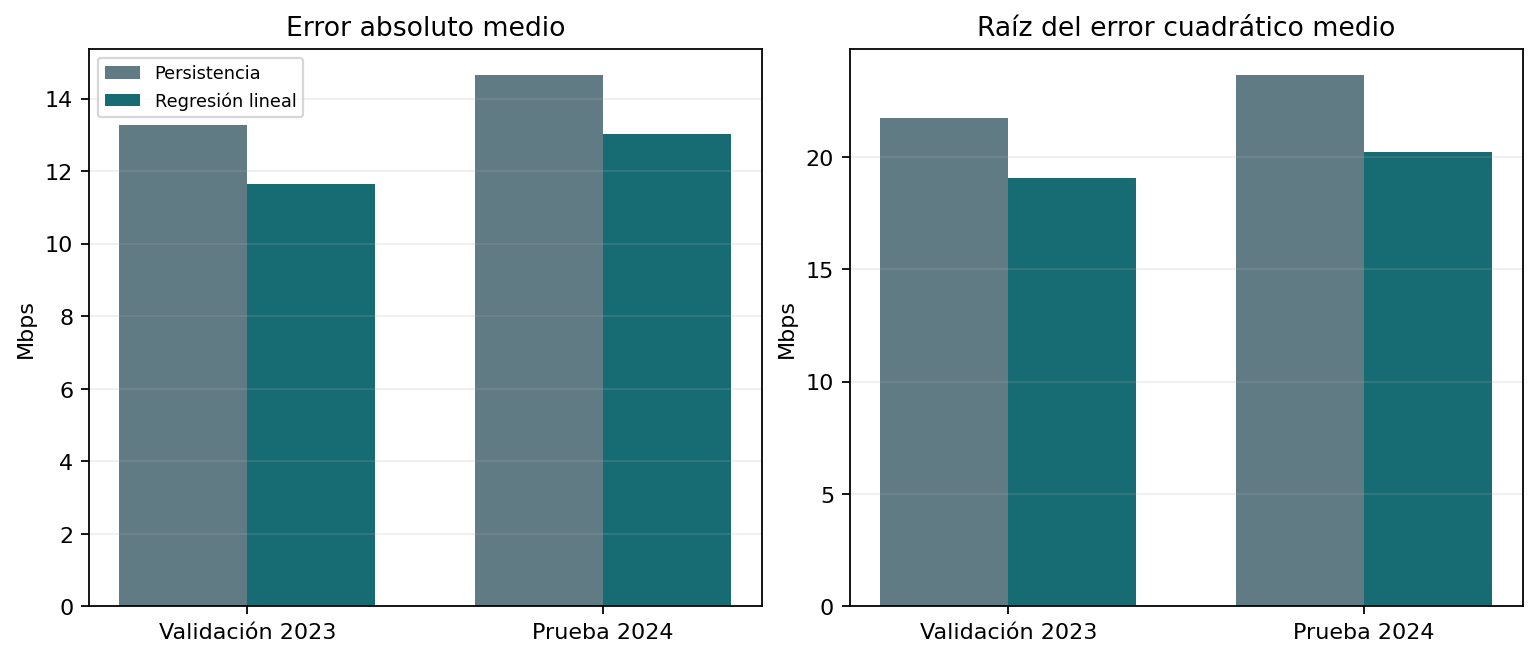

s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/modelo_errores.png


In [12]:
def regression_metrics(frame, column):
    error = F.col(column) - F.col("objetivo")
    row = frame.agg(F.count("*").alias("n"), F.avg(F.abs(error)).alias("mae"),
                    F.avg(error * error).alias("mse"), F.avg(error).alias("bias"),
                    F.var_pop("objetivo").alias("variance")).first()
    if not row.n:
        raise ValueError("Una partición de evaluación quedó vacía.")
    return {"n": row.n, "mae_mbps": row.mae, "rmse_mbps": row.mse**0.5,
            "sesgo_mbps": row.bias, "r2": 1 - row.mse / row.variance if row.variance else None}


def compare_models(predictions, root):
    rows = []
    for key, year in (("validacion", 2023), ("prueba", 2024)):
        frame = predictions.filter(F.col("particion") == key)
        for method, column in (("Persistencia", "vel_descarga_mbps"), ("Regresión lineal", "regresion")):
            rows.append({"particion": key, "year_objetivo": year, "modelo": method,
                         **regression_metrics(frame, column)})
    show_rows(rows)
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4), constrained_layout=True)
    for ax, metric, title in zip(axes, ("mae_mbps", "rmse_mbps"), ("Error absoluto medio", "Raíz del error cuadrático medio")):
        ax.bar([-.18, .82], [rows[0][metric], rows[2][metric]], .36, color="#607B83", label="Persistencia")
        ax.bar([.18, 1.18], [rows[1][metric], rows[3][metric]], .36, color=TEAL, label="Regresión lineal")
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Validación 2023", "Prueba 2024"])
        ax.set_title(title)
        ax.set_ylabel("Mbps")
        ax.grid(axis="y", alpha=.2)
    axes[0].legend(fontsize=8)
    return rows, persist_figure(fig, root, "modelo_errores.png")

scores, chart_model = compare_models(predictions, root)

## 13. Diagnóstico de errores por departamento

Un sesgo positivo indica sobreestimación. La cantidad de pares permite interpretar métricas calculadas sobre grupos pequeños.

In [13]:
def test_diagnostics(frame):
    result = (frame.filter("particion = 'prueba'").groupBy("departamento").agg(
        F.count("*").alias("pares"),
        F.avg(F.abs(F.col("vel_descarga_mbps") - F.col("objetivo"))).alias("mae_persistencia_mbps"),
        F.avg(F.abs(F.col("regresion") - F.col("objetivo"))).alias("mae_regresion_mbps"),
        F.avg(F.col("regresion") - F.col("objetivo")).alias("sesgo_regresion_mbps"),
    ).orderBy(F.col("pares").desc(), "departamento").toPandas())
    display(result.round(3))
    return finite_records(result)
diagnostics = test_diagnostics(predictions)

,departamento,pares,mae_persistencia_mbps,mae_regresion_mbps,sesgo_regresion_mbps
0,CUSCO,435,13.683,12.575,-8.625
1,LIMA,425,14.652,15.964,-12.013
2,JUNIN,398,14.640,12.734,-6.575
3,CAJAMARCA,392,17.148,13.179,-6.211
4,ANCASH,388,15.665,13.490,-6.798
5,PUNO,383,14.061,12.032,-6.021
6,AREQUIPA,346,16.083,14.788,-10.196
7,AYACUCHO,337,14.441,12.794,-7.823
8,LA LIBERTAD,279,12.571,10.651,-3.939
9,HUANCAVELICA,274,14.584,13.137,-8.769


## 14. Publicación de gráficas y métricas

In [14]:
eda_charts = [uri for uri in (chart_trend, chart_dept, chart_speeds, chart_pop, chart_coverage) if uri]
charts = [*eda_charts, chart_model]
model_report = {"linea_base": "persistencia", "metrica_principal": "MAE (Mbps)", "train_n": train_n,
                "coeficiente": model_fit["coeficiente_velocidad_origen"], "intercepto": model_fit["intercepto"],
                "particiones": partition_summary, "metricas": scores, "prueba_por_departamento": diagnostics}
report = {"gold_manifest_uri": GOLD_RUN_URI, "silver_manifest_uri": manifest["silver_manifest_uri"],
          "bronze_manifest_uri": manifest["bronze_manifest_uri"], "application_id": spark.sparkContext.applicationId,
          "spark_event_log_uri": events_uri, "quality": quality, "charts": charts,
          "eda": {"charts": eda_charts, "trimestres": quarterly, "departamentos_2024_t4": departmental,
                  "distribucion_2024_t4": speed_stats, "population_sample_n": population_stats["distritos_en_grafica"],
                  "population_spearman": population_stats["spearman"], "poblacion_pruebas": population_stats,
                  "osiptel_corte": osiptel_cut, "osiptel_4g": coverage_table},
          "modelo": model_report}
resultado = {**report, "metricas_uri": save_json(f"{root}/metricas.json", report)}
show_values({"Métricas y diagnóstico": resultado["metricas_uri"], "Gráficas publicadas": len(charts),
             "Eventos Spark": events_uri})
show_rows([{"grafica": uri.rsplit("/", 1)[1], "uri": uri} for uri in charts])
resources.close()

,Indicador,Valor
0,Métricas y diagnóstico,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/metricas.json
1,Gráficas publicadas,6
2,Eventos Spark,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/eventos_spark/


,grafica,uri
0,eda_trimestres.png,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_trimestres.png
1,eda_departamentos.png,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_departamentos.png
2,eda_distribucion_2024_t4.png,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_distribucion_2024_t4.png
3,eda_poblacion_pruebas.png,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_poblacion_pruebas.png
4,eda_osiptel_4g.png,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/eda_osiptel_4g.png
5,modelo_errores.png,s3://american-tower-dev-operations-1dd72256126674a5893dfca3df/run_id=20261125T080507Z-f8de12bfa0/analisis/modelo_errores.png
